# Taller 1: Redes Neuronales Artificiales (MLP) - Clasificación y Regresión
**Materia:** Aprendizaje Avanzado  
**Autores:** Miguel Ángel Ortiz Roldán  
**Archivo de Entrega:** `Taller1_MiguelAngelOrtiz.ipynb`
**Video:** https://youtu.be/TYiXG4_Ykmk
---

## 1. Introducción
El **Perceptrón Multicapa (MLP)** es una de las arquitecturas fundamentales del Deep Learning, capaz de actuar como aproximador universal tanto de funciones continuas en problemas de regresión como de superficies de decisión complejas y no lineales en problemas de clasificación (Caicedo & López, 2009, pp. 76–86).

En este taller se abordan los dos pilares del aprendizaje supervisado utilizando conjuntos de datos de referencia a gran escala provenientes del **UCI Machine Learning Repository**:
1. **Punto 1 (Clasificación Multiclase):** Identificación morfológica de 7 variedades de granos en el **Dry Bean Dataset**.
2. **Punto 2 (Regresión Continua):** Predicción de la demanda horaria de alquiler de bicicletas en el **Bike Sharing Dataset**.

Se evalúa sistemáticamente el impacto de **3 arquitecturas de red** (máximo 2 capas ocultas) y **3 optimizadores** (`Adam`, `RMSprop` y `SGD con momentum`) en ambos dominios.

> **Nota metodológica:** Se solicitaron 3 optimizadores para la comparativa. Se seleccionó un enfoque clásico y base de la teoría del curso (`SGD con momentum`), la opción vista en clase para Keras que resuelve la escala del paso (`RMSprop`), y el estándar moderno actual de la industria (`Adam`).

---

## 2. Marco Teórico
- **Perceptrón Multicapa (MLP):** Red neuronal feedforward densamente conectada entrenada mediante retropropagación del error (*backpropagation*).
- **Adaptación Arquitectónica según la Tarea:**
  - **Clasificación Multiclase:** Capa de salida con activación `Softmax` ($S(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$) y función de pérdida `Sparse Categorical Crossentropy`.
  - **Regresión Continua:** Capa de salida con activación `Linear` ($f(z) = z$) y función de pérdida `Mean Squared Error (MSE)`.
- **Optimizadores Evaluados:**
  - **SGD con Momentum:** Implementación del Descenso de Gradiente visto en clase (Caicedo & López, Cap. 2 y 3), incorporando un término de inercia (*momentum*) para acelerar la convergencia en direcciones persistentes y suavizar oscilaciones.
  - **RMSprop:** Propuesto por Geoffrey Hinton (2012, Universidad de Toronto); normaliza el gradiente dividiéndolo por la raíz del promedio móvil del cuadrado de los gradientes recientes, adaptando el tamaño del paso por parámetro.
  - **Adam (*Adaptive Moment Estimation*):** Propuesto por Kingma y Ba (2014); estándar actual de la industria que combina la inercia direccional de *Momentum* (primer momento) con la tasa adaptativa de *RMSprop* (segundo momento) y corrección de sesgo.
- **Métricas de Evaluación:**
  - **Clasificación Multiclase (Dry Bean):**

    Accuracy (Exactitud): Porcentaje global de predicciones correctas sobre el total. (¿Qué fracción de granos clasificó bien la red en general?).

    Precision (Macro): Calidad de las predicciones positivas. (De los granos que el modelo dijo que eran 'Cali', ¿cuántos realmente eran 'Cali'?). Evita falsas alarmas.

    Recall / Sensibilidad (Macro): Cobertura o tasa de detección. (De todos los frijoles 'Cali' reales que existían, ¿cuántos logró encontrar el modelo?). Evita omisiones.
    
    F1-Score (Macro): Promedio armónico entre Precision y Recall. Es la métrica reina para evaluar el rendimiento equilibrado entre clases.

    Matriz de Confusión: Tabla bidimensional que mapea las clases reales vs. predichas, permitiendo identificar patrones específicos de confusión entre variedades.

  - **Regresión Continua (Bike Sharing):**

    MAE (Error Absoluto Medio): Promedio lineal de los errores en magnitud absoluta (|y−^y|). Responde a: "En promedio, ¿por cuántas bicicletas nos equivocamos en cada predicción?". Es intuitivo y no sobrepenaliza fallos atípicos.

    MSE (Error Cuadrático Medio): Promedio de los errores al cuadrado ((y−^y)2). Penaliza con severidad desproporcionada los errores grandes (un error de 10 bicis suma 100, pero uno de 50 suma 2,500).

    RMSE (Raíz del Error Cuadrático Medio): Raíz cuadrada del MSE (√MSE). Mantiene la penalización severa a los errores grandes pero devuelve la magnitud a la escala original (número de bicicletas).
    
    R² (Coeficiente de Determinación): Proporción de la varianza del objetivo explicada por el modelo (rango ≤1.0). Responde a: "¿Qué porcentaje de la variación en la demanda horaria explica la red neuronal en comparación con una predicción trivial del promedio?".



## 3. Explicación Datos

* **Dry Bean Dataset** Contiene **13,611 registros** de granos de fríjol seco con 16 características biométricas y geométricas (como área, perímetro, excentricidad, compacidad y factores de forma) obtenidas mediante visión artificial sobre imágenes en alta resolución[2][3].
* **Objetivo:** Clasificar automáticamente cada grano dentro de **7 variedades morfológicas** registradas en Turquía (*Dermason, Sira, Seker, Horoz, Cali, Barbunya y Bombay*), reduciendo costos y errores en la certificación e inspección agrícola

* **Bike Sharing Dataset** Registra **17,379 observaciones horarias** del sistema de transporte *Capital Bikeshare* en Washington D.C. (2011-2012), combinando información meteorológica (temperatura, humedad, condición del clima, velocidad del viento) y atributos temporales (hora, día laboral, festivos, estación del año)[4][5].
* **Objetivo:** Estimar o predecir la **demanda horaria total de alquiler de bicicletas** (variable objetivo `cnt`), facilitando la logística operacional para redistribuir la flota entre estaciones y evitar desabastecimientos en horas pico

In [2]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Preprocesamiento, codificación y métricas
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, 
    precision_score, recall_score, f1_score,
    r2_score, mean_squared_error, mean_absolute_error
)

# Deep Learning con TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

# Reproducibilidad global
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow versión: {tf.__version__}")

I0000 00:00:1789940478.276665   74248 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789940478.321370   74248 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow versión: 2.21.0


I0000 00:00:1789940479.219948   74248 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 4. Planteamiento de la Solución: Funciones Modulares Reutilizables

Diseñamos una suite de funciones modulares genéricas que aplican tanto para problemas de **Clasificación** como de **Regresión**, garantizando separación de responsabilidades y reutilización de código.

In [ ]:
# ==============================================================================
# SUITE MODULAR UNIVERSAL (CLASIFICACIÓN & REGRESIÓN)
# ==============================================================================

def cargar_datos(ruta: str, nombre_problema: str = "Dataset") -> pd.DataFrame:
    """Carga un dataset CSV y muestra un resumen inicial."""
    df = pd.read_csv(ruta)
    print(f"✓ [{nombre_problema}] Cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")
    return df

def auditar_calidad_datos(df: pd.DataFrame, col_target: str, tipo: str = 'clasificacion', 
                          col_tiempo: str = None, col_ciclo: str = None) -> None:
    """
    Audita datos nulos y grafica la variable objetivo de forma 100% genérica.
    - tipo='clasificacion': Gráfico de barras con conteo exacto por clase.
    - tipo='regresion':
        * Sin variables temporales: Histograma global con etiquetas numéricas y KDE.
        * Con col_tiempo y col_ciclo: Dashboard analítico completo de 3 paneles:
            1. Distribución global de todo el dataset con conteos por barra.
            2. Evolución temporal histórica a lo largo del tiempo (col_tiempo).
            3. Ciclo horario/periódico promedio (col_ciclo: 0 a 23h).
    """
    import matplotlib.dates as mdates
    total_nulos = df.isnull().sum().sum()
    
    estado = "(100% íntegro)" if total_nulos == 0 else "(Atención: Requiere imputación/limpieza)"
    print(f"✓ Auditoría de nulos: {total_nulos} valores faltantes {estado}.")

    
    if tipo == 'clasificacion':
        plt.figure(figsize=(8, 4))
        ax = sns.countplot(data=df, x=col_target, hue=col_target, palette='viridis', legend=False)
        ax.bar_label(ax.containers[0], fontsize=9)
        plt.title(f'Distribución de Clases ({col_target})', fontsize=11, fontweight='bold', pad=10)
        plt.xlabel(f'Clases ({col_target})', fontsize=10)
        plt.ylabel('Cantidad de Registros', fontsize=10)
        plt.xticks(rotation=30, ha='right')
        sns.despine()
        plt.tight_layout()
        plt.show()
    else:
        if col_tiempo is not None and col_ciclo is not None and col_tiempo in df.columns and col_ciclo in df.columns:
            # Dashboard de 3 Paneles (Global + Serie Temporal + Ciclo Horario)
            fig = plt.figure(figsize=(15, 9.5))
            gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
            ax1 = fig.add_subplot(gs[0, 0])
            ax2 = fig.add_subplot(gs[0, 1])
            ax3 = fig.add_subplot(gs[1, :])
            
            # Panel 1: Distribución Global
            ax0 = sns.histplot(df[col_target], kde=True, color='#3b82f6', bins=10, ax=ax1, edgecolor='white', alpha=0.7)
            media = df[col_target].mean()
            mediana = df[col_target].median()
            for p in ax0.patches:
                h = p.get_height()
                if h > 0:
                    ax0.annotate(f'{int(h):,}', 
                                 (p.get_x() + p.get_width() / 2., h), 
                                 ha='center', va='bottom', fontsize=8, fontweight='bold',
                                 xytext=(0, 3), textcoords='offset points')
            ax1.axvline(mediana, color='#10b981', linestyle='--', linewidth=2, label=f'Mediana = {mediana:.1f}')
            ax1.axvline(media, color='#ef4444', linestyle=':', linewidth=2, label=f'Media = {media:.1f}')
            ax1.set_title(f'1. Distribución Global de {col_target} (Horas por Rango)', fontsize=11, fontweight='bold', pad=10)
            ax1.set_xlabel(f'Rango de {col_target} (Bicicletas por Hora)', fontsize=10)
            ax1.set_ylabel('Frecuencia (Horas Registradas)', fontsize=10)
            ax1.set_ylim(0, ax1.get_ylim()[1] * 1.08)
            ax1.legend(loc='upper right')
            
            # Panel 2: Evolución temporal histórica
            fechas = pd.to_datetime(df[col_tiempo])
            df_temp = df.groupby(fechas)[col_target].sum().reset_index()
            ax2.plot(df_temp[col_tiempo], df_temp[col_target], color='#0284c7', lw=1.2, alpha=0.75, label=f'Total Diario {col_target}')
            df_temp['tendencia_7d'] = df_temp[col_target].rolling(7).mean()
            ax2.plot(df_temp[col_tiempo], df_temp['tendencia_7d'], color='#ef4444', lw=2, label='Tendencia Móvil (7 días)')
            ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
            ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
            ax2.set_title(f'2. Evolución Temporal según {col_tiempo} (2011 - 2012)', fontsize=11, fontweight='bold', pad=10)
            ax2.set_xlabel(f'Fecha ({col_tiempo})', fontsize=10)
            ax2.set_ylabel(f'Total Diario de {col_target}', fontsize=10)
            ax2.grid(True, linestyle='--', alpha=0.4)
            ax2.legend(loc='upper left')
            
            # Panel 3: Demanda promedio por hora del día
            sns.barplot(data=df, x=col_ciclo, y=col_target, color='#2563eb', errorbar=None, ax=ax3)
            ax3.bar_label(ax3.containers[0], fmt='%.0f', fontsize=8.5, padding=2)
            ax3.set_title(f'3. Demanda Promedio según la Hora del Día ({col_ciclo}: 0 a 23 h)', fontsize=11, fontweight='bold', pad=10)
            ax3.set_xlabel(f'Hora del Día ({col_ciclo}: 0 a 23 h)', fontsize=10)
            ax3.set_ylabel(f'Cantidad Promedio de {col_target}', fontsize=10)
            ax3.grid(axis='y', linestyle='--', alpha=0.4)
            
            sns.despine()
            plt.tight_layout()
            plt.show()
        elif col_tiempo is not None and col_tiempo in df.columns:
            fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
            # Fallback 2 paneles si solo se pasa col_tiempo
            ax0 = sns.histplot(df[col_target], kde=True, color='#3b82f6', bins=10, ax=axes[0], edgecolor='white', alpha=0.7)
            media = df[col_target].mean()
            mediana = df[col_target].median()
            for p in ax0.patches:
                h = p.get_height()
                if h > 0:
                    ax0.annotate(f'{int(h):,}', (p.get_x() + p.get_width()/2., h), ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0,3), textcoords='offset points')
            axes[0].axvline(mediana, color='#10b981', linestyle='--', linewidth=2, label=f'Mediana = {mediana:.1f}')
            axes[0].axvline(media, color='#ef4444', linestyle=':', linewidth=2, label=f'Media = {media:.1f}')
            axes[0].set_title(f'Distribución Global de {col_target}', fontsize=11, fontweight='bold')
            axes[0].set_xlabel(f'Valor de {col_target}', fontsize=10)
            axes[0].set_ylabel('Frecuencia (Registros)', fontsize=10)
            axes[0].legend(loc='upper right')
            
            fechas = pd.to_datetime(df[col_tiempo])
            df_temp = df.groupby(fechas)[col_target].sum().reset_index()
            axes[1].plot(df_temp[col_tiempo], df_temp[col_target], color='#0284c7', lw=1.2, alpha=0.75, label=f'Total Diario {col_target}')
            df_temp['tendencia_7d'] = df_temp[col_target].rolling(7).mean()
            axes[1].plot(df_temp[col_tiempo], df_temp['tendencia_7d'], color='#ef4444', lw=2, label='Tendencia Móvil (7 días)')
            axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
            axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
            axes[1].set_title(f'Evolución Temporal de {col_target} según {col_tiempo}', fontsize=11, fontweight='bold')
            axes[1].set_xlabel(f'Fecha ({col_tiempo})', fontsize=10)
            axes[1].set_ylabel(f'Total Diario de {col_target}', fontsize=10)
            axes[1].grid(True, linestyle='--', alpha=0.4)
            axes[1].legend(loc='upper left')
            sns.despine()
            plt.tight_layout()
            plt.show()
        else:
            plt.figure(figsize=(8.5, 4.5))
            ax = sns.histplot(df[col_target], kde=True, color='#3b82f6', bins=10, edgecolor='white', alpha=0.7)
            media = df[col_target].mean()
            mediana = df[col_target].median()
            for p in ax.patches:
                h = p.get_height()
                if h > 0:
                    ax.annotate(f'{int(h):,}', (p.get_x() + p.get_width()/2., h), ha='center', va='bottom', fontsize=8.5, fontweight='bold', xytext=(0,3), textcoords='offset points')
            plt.axvline(mediana, color='#10b981', linestyle='--', linewidth=2, label=f'Mediana = {mediana:.1f}')
            plt.axvline(media, color='#ef4444', linestyle=':', linewidth=2, label=f'Media = {media:.1f}')
            plt.title(f'Distribución Global de {col_target}', fontsize=11, fontweight='bold', pad=12)
            plt.xlabel(f'Rango de {col_target}', fontsize=10)
            plt.ylabel('Frecuencia (Cantidad de Horas)', fontsize=10)
            plt.ylim(0, plt.ylim()[1] * 1.08)
            plt.legend(loc='upper right')
            sns.despine()
            plt.tight_layout()
            plt.show()

def preparar_datos(df: pd.DataFrame, col_target: str, cols_a_eliminar: list = None, 
                   tipo: str = 'clasificacion', test_size: float = 0.20, random_state: int = 42):
    """
    Preprocesa características, realiza split estratificado (si es clasificación) y estandariza con StandardScaler.
    Retorna: X_train_s, X_test_s, y_train, y_test, scaler, le (LabelEncoder si aplica)
    """
    cols_drop = [col_target] + (cols_a_eliminar if cols_a_eliminar else [])
    X = df.drop(columns=cols_drop)
    y = df[col_target]
    
    "El labelencoder y el stratify solo se usan en clasificación por eso se incializan en none"
    le = None
    stratify = None


    if tipo == 'clasificacion':
        if y.dtype == 'object' or isinstance(y.iloc[0], str):
            le = LabelEncoder()
            y = le.fit_transform(y)
        stratify = y
        
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=stratify
    )
    
    """La Estandarización de Datos, todas las colunas se estandarizan con el Z-score para que
    para que todos los datos tengan la misma magnitud
    fit_transform(X_train): El escalador analiza únicamente los datos de entrenamiento
    transform(X_test): Transforma los datos de prueba utilizando los mismos parámetros matemáticos que aprendió de X_train
    """
    
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    
    print(f"✓ Datos procesados: Train {X_train_s.shape}, Test {X_test_s.shape} | Variables: {X.shape[1]}")
    return X_train_s, X_test_s, y_train, y_test, scaler, le


In [ ]:
# Optimizadores y construcción del modelo


def obtener_optimizador(nombre: str, lr: float = 0.001):
    """Crea la instancia del optimizador con Gradient Clipping para estabilidad numérica."""
    nombre = nombre.lower()
    if nombre == 'adam':
        return optimizers.Adam(learning_rate=lr, clipnorm=1.0)
    elif nombre == 'rmsprop':
        return optimizers.RMSprop(learning_rate=lr, clipnorm=1.0)
    elif nombre == 'sgd':
        # SGD requiere learning rate prudente y clipnorm para evitar explosión de gradientes en regresión
        return optimizers.SGD(learning_rate=0.0001, momentum=0.9, clipnorm=1.0)
    else:
        raise ValueError(f"Optimizador '{nombre}' no soportado.")


def construir_mlp(id_arquitectura: int, input_dim: int, output_dim: int, 
                  tipo: str = 'clasificacion', optimizador: str = 'adam', lr: float = 0.001) -> models.Sequential:
    """
    Construye y compila el MLP adaptando la capa de salida y loss según clasificación o regresión.
    - Arq 1 (1 capa oculta): 32 neuronas + Dropout
    - Arq 2 (2 capas pirámide): 64 -> 32 neuronas
    - Arq 3 (2 capas profundas con regularización): 128 -> 64 neuronas + Doble Dropout
    """
    modelo = models.Sequential()
    modelo.add(layers.Input(shape=(input_dim,)))
    
    """Notas:Las capas ocultas (El "Cerebro") son idénticas en ambas:
    Las capas intermedias (las de 128, 64, 32 neuronas con activación ReLU) 
    hacen exactamente el mismo trabajo en ambos problemas: 
    extraer patrones y encontrar relaciones complejas entre las variables.
    A ese "cerebro" no le importa si los datos son de granos de fríjol o de bicicletas. "
    """
    if id_arquitectura == 1:
        modelo.add(layers.Dense(32, activation='relu', name='oculta_1'))
        modelo.add(layers.Dropout(0.2, name='dropout_1'))
    elif id_arquitectura == 2:
        modelo.add(layers.Dense(64, activation='relu', name='oculta_1'))
        modelo.add(layers.Dense(32, activation='relu', name='oculta_2'))
    elif id_arquitectura == 3:
        modelo.add(layers.Dense(128, activation='relu', name='oculta_1'))
        modelo.add(layers.Dropout(0.3, name='dropout_1'))
        modelo.add(layers.Dense(64, activation='relu', name='oculta_2'))
        modelo.add(layers.Dropout(0.2, name='dropout_2'))
    else:
        raise ValueError("id_arquitectura debe ser 1, 2 o 3.")
        
   
    """La última capa (La "Boca") cambia según la pregunta:
    Lo único que cambia es la forma en que la red te da la respuesta final:

    Clasificación Multiclase (Granos de fríjol) 
    Funcion_activacion= Softmax Convierte la salida en probabilidades porcentuales que suman 100% 
    Categorical Crossentropy Castiga al modelo si le dio poca probabilidad al grano correcto.

    Regresión Continua (Bicicletas) Funcion_activacion= Linear "¿Cuántas bicicletas exactamente se van a alquilar en esta hora?" 
    Mean Squared Error (MSE) Mide qué tan lejos estuvo del número real restando $(Real - Predicho)^2$.
    """

    # Capa de salida y compilación según el tipo de tarea
    opt = obtener_optimizador(optimizador, lr)
    if tipo == 'clasificacion':
        modelo.add(layers.Dense(output_dim, activation='softmax', name='salida_clasificacion'))
        modelo.compile(
            optimizer=opt,
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
    else: # Regresion
        modelo.add(layers.Dense(1, activation='linear', name='salida_regresion'))
        modelo.compile(
            optimizer=opt,
            loss='mean_squared_error',
            metrics=['mae', tf.keras.metrics.RootMeanSquaredError(name='rmse')]
        )
    return modelo

## 4.1 Diagramas de las arquitecturas MLP

Las tres arquitecturas cumplen la restricción de utilizar como máximo dos capas ocultas. La capa de salida se adapta al problema: produce 7 probabilidades para clasificación y 1 valor continuo para regresión.

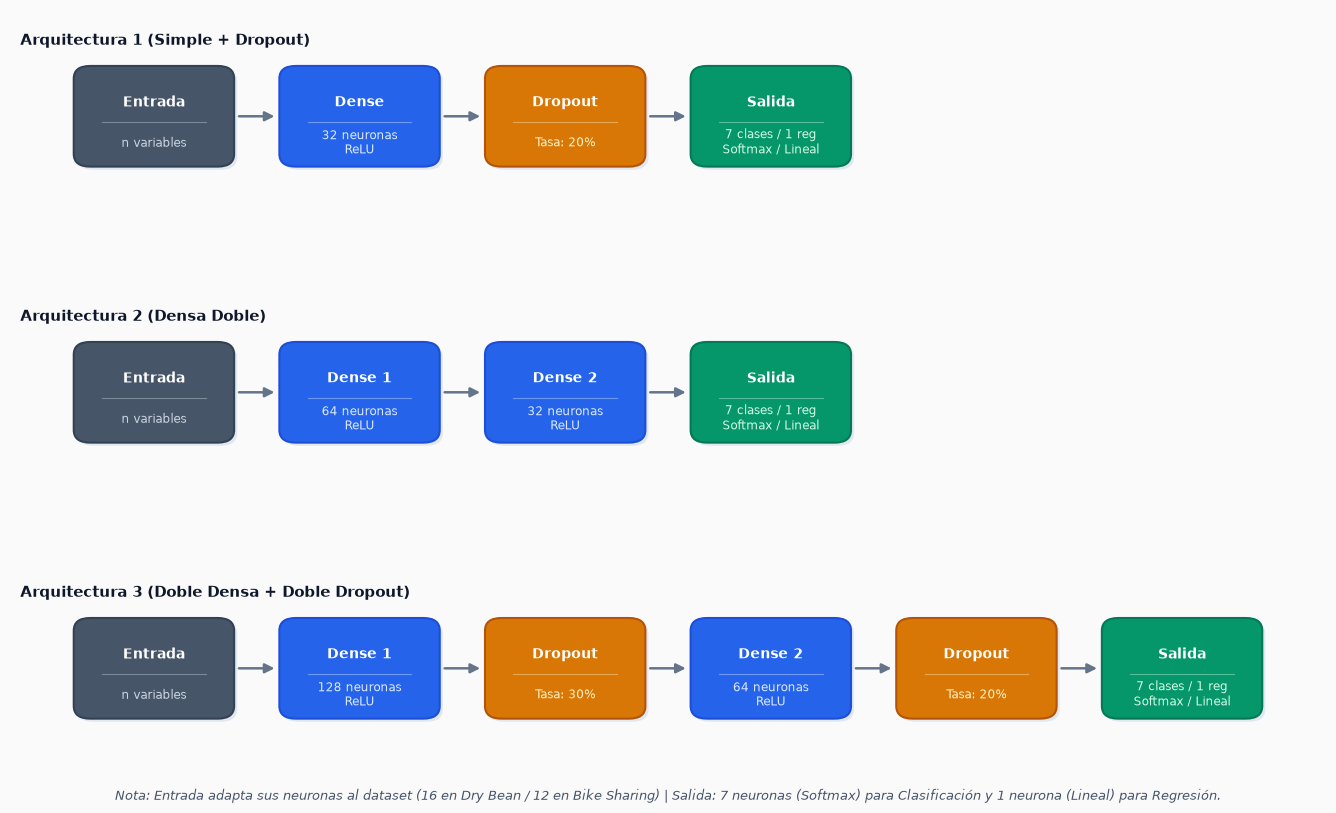

In [6]:
# Diagramas de las tres arquitecturas evaluadas
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.pyplot as plt

def dibujar_arquitectura(ax, titulo, capas, max_capas=6):
    ax.set_facecolor('#FAFAFA')
    # Margen holgado para que NUNCA se corte la entrada ni la salida
    ax.set_xlim(-0.7, max_capas - 0.3)
    ax.set_ylim(-0.15, 1.15)
    ax.axis('off')

    ax.text(-0.65, 0.95, titulo, fontsize=11, fontweight='bold', color='#0F172A', ha='left', va='center')

    colores = {
        'entrada': {'box': '#475569', 'border': '#334155', 'text': '#FFFFFF', 'sub': '#CBD5E1'},
        'oculta':  {'box': '#2563EB', 'border': '#1D4ED8', 'text': '#FFFFFF', 'sub': '#DBEAFE'},
        'dropout': {'box': '#D97706', 'border': '#B45309', 'text': '#FFFFFF', 'sub': '#FEF3C7'},
        'salida':  {'box': '#059669', 'border': '#047857', 'text': '#FFFFFF', 'sub': '#D1FAE5'},
    }

    ancho_caja = 0.72
    alto_caja = 0.58
    y_caja = 0.18

    for idx, (nombre, detalle, tipo) in enumerate(capas):
        cfg = colores[tipo]

        # Sombra sutil
        sombra = FancyBboxPatch(
            (idx - ancho_caja/2 + 0.015, y_caja - 0.02), ancho_caja, alto_caja,
            boxstyle='round,pad=0.03,rounding_size=0.08',
            facecolor='#E2E8F0', edgecolor='none', zorder=1
        )
        ax.add_patch(sombra)

        # Tarjeta principal
        caja = FancyBboxPatch(
            (idx - ancho_caja/2, y_caja), ancho_caja, alto_caja,
            boxstyle='round,pad=0.03,rounding_size=0.08',
            facecolor=cfg['box'], edgecolor=cfg['border'], linewidth=1.5, zorder=2
        )
        ax.add_patch(caja)

        # Título
        ax.text(idx, y_caja + alto_caja * 0.65, nombre,
                ha='center', va='center', color=cfg['text'],
                fontsize=10, fontweight='bold', zorder=3)

        # Divisor interno
        ax.plot([idx - ancho_caja*0.35, idx + ancho_caja*0.35], 
                [y_caja + alto_caja * 0.44, y_caja + alto_caja * 0.44],
                color=cfg['sub'], linewidth=0.8, alpha=0.4, zorder=3)

        # Detalle
        ax.text(idx, y_caja + alto_caja * 0.22, detalle,
                ha='center', va='center', color=cfg['sub'],
                fontsize=8.5, linespacing=1.2, zorder=3)

        # Flecha conectora
        if idx < len(capas) - 1:
            x_inicio = idx + ancho_caja / 2 + 0.04
            x_fin = (idx + 1) - ancho_caja / 2 - 0.04
            y_flecha = y_caja + alto_caja / 2

            ax.add_patch(FancyArrowPatch(
                (x_inicio, y_flecha), (x_fin, y_flecha),
                arrowstyle='-|>', mutation_scale=14, linewidth=1.8,
                color='#64748B', zorder=2
            ))

arquitecturas = {
    'Arquitectura 1 (Simple + Dropout)': [
        ('Entrada', 'n variables', 'entrada'),
        ('Dense', '32 neuronas\nReLU', 'oculta'),
        ('Dropout', 'Tasa: 20%', 'dropout'),
        ('Salida', '7 clases / 1 reg\nSoftmax / Lineal', 'salida'),
    ],
    'Arquitectura 2 (Densa Doble)': [
        ('Entrada', 'n variables', 'entrada'),
        ('Dense 1', '64 neuronas\nReLU', 'oculta'),
        ('Dense 2', '32 neuronas\nReLU', 'oculta'),
        ('Salida', '7 clases / 1 reg\nSoftmax / Lineal', 'salida'),
    ],
    'Arquitectura 3 (Doble Densa + Doble Dropout)': [
        ('Entrada', 'n variables', 'entrada'),
        ('Dense 1', '128 neuronas\nReLU', 'oculta'),
        ('Dropout', 'Tasa: 30%', 'dropout'),
        ('Dense 2', '64 neuronas\nReLU', 'oculta'),
        ('Dropout', 'Tasa: 20%', 'dropout'),
        ('Salida', '7 clases / 1 reg\nSoftmax / Lineal', 'salida'),
    ],
}

fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), facecolor='#FAFAFA')
max_capas = max(len(c) for c in arquitecturas.values())

for ax, (titulo, capas) in zip(axes, arquitecturas.items()):
    dibujar_arquitectura(ax, titulo, capas, max_capas)

fig.text(0.5, 0.02, 
         "Nota: Entrada adapta sus neuronas al dataset (16 en Dry Bean / 12 en Bike Sharing) | "
         "Salida: 7 neuronas (Softmax) para Clasificación y 1 neurona (Lineal) para Regresión.",
         ha='center', fontsize=9.5, color='#475569', fontstyle='italic')

plt.subplots_adjust(left=0.03, right=0.97, top=0.95, bottom=0.06, hspace=0.35)
plt.show()


---
# PARTE 1: PUNTO 1 - CLASIFICACIÓN MULTICLASE (DRY BEAN DATASET)

### 🌾 Contexto del Problema:
En la industria agroalimentaria, la clasificación de semillas de fríjol seco para certificación y exportación se realizaba históricamente de forma manual, lo que genera altos costos y margen de error humano. Este conjunto de datos recopila imágenes en alta resolución de **13,611 granos** pertenecientes a 7 variedades registradas en Turquía. Mediante técnicas de visión artificial, cada grano fue segmentado para extraer sus propiedades geométricas y biométricas sin destruirlo.

### 📋 Ficha Técnica del Dataset:
| Atributo | Detalle |
| :--- | :--- |
| **Fuente Oficial** | UCI Machine Learning Repository (Koklu & Ozkan, 2020) |
| **Volumen** | **13,611 registros** (granos) y 17 columnas (16 características + 1 objetivo) |
| **Tipo de Variables** | 16 numéricas continuas (medidas morfológicas exactas) |
| **Variable Objetivo ($y$)** | `Class` (7 categorías: *Dermason, Sira, Seker, Horoz, Cali, Barbunya, Bombay*) |


### 🔬 Entradas de la Red Neuronal ($X$):
- **Dimensiones básicas:** `Area` (área en píxeles), `Perimeter` (circunferencia del borde), `MajorAxisLength` (longitud del eje mayor), `MinorAxisLength` (eje menor).
- **Morfología y forma:** `AspectRation` (proporción largo/ancho), `Eccentricity` (excentricidad elíptica), `ConvexArea`, `EquivDiameter`, `Extent`, `Solidity` (solidez estructural), `roundness` (redondez), `Compactness` (compacidad).
- **Factores de forma específicos:** `ShapeFactor1`, `ShapeFactor2`, `ShapeFactor3`, `ShapeFactor4` (descriptores matemáticos invariantes a escala).

✓ [Punto 1: Dry Bean] Cargado con éxito: 13611 filas y 17 columnas.
✓ Auditoría de nulos: 0 valores faltantes (100% íntegro).


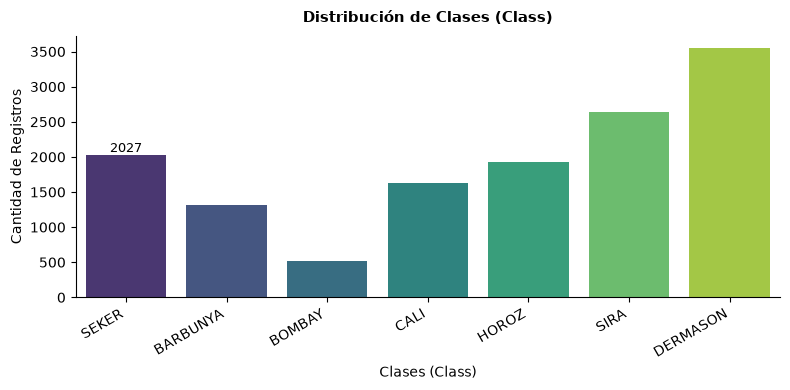

✓ Datos procesados: Train (10888, 16), Test (2723, 16) | Variables: 16
Clases a clasificar: 7 clases (['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA'])


In [4]:
# 1. Carga y Auditoría de Dry Bean
ruta_bean = '../Data_entrenamiento/Punto_1_Clasificacion/Dry_Bean_Dataset.csv'
df_bean = cargar_datos(ruta_bean, "Punto 1: Dry Bean")
auditar_calidad_datos(df_bean, col_target='Class', tipo='clasificacion')

# 2. Preparación y escalado de datos
X_train_c, X_test_c, y_train_c, y_test_c, scaler_c, le_bean = preparar_datos(
    df=df_bean, col_target='Class', tipo='clasificacion'
)
num_clases_bean = len(np.unique(y_train_c))
print(f"Clases a clasificar: {num_clases_bean} clases ({list(le_bean.classes_)})")

In [5]:
# 3. Experimentación Sistemática (3 Arquitecturas x 3 Optimizadores = 9 Modelos)
arqs = [1, 2, 3]
opts = ['adam', 'rmsprop', 'sgd']
input_dim_c = X_train_c.shape[1]

resultados_clasif = []
historias_clasif = {}
modelos_clasif = {}

print("Entrenando 9 configuraciones para Clasificación (Dry Bean)...")
for arq in arqs:
    for opt in opts:
        nombre = f"Arq_{arq}_{opt}"
        print(f"-> {nombre}...", end=" ")
        
        m = construir_mlp(arq, input_dim_c, num_clases_bean, tipo='clasificacion', optimizador=opt, lr=0.001)
        h = m.fit(
            X_train_c, y_train_c, 
            epochs=40, batch_size=64, 
            validation_data=(X_test_c, y_test_c), 
            verbose=0
        )
        
        y_prob = m.predict(X_test_c, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        
        acc = accuracy_score(y_test_c, y_pred)
        f1 = f1_score(y_test_c, y_pred, average='macro', zero_division=0)
        prec = precision_score(y_test_c, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test_c, y_pred, average='macro', zero_division=0)
        
        resultados_clasif.append({
            'Experimento': nombre,
            'Arquitectura': f"Arq {arq}",
            'Optimizador': opt.upper(),
            'Accuracy': round(acc, 4),
            'Precision Macro': round(prec, 4),
            'Recall Macro': round(rec, 4),
            'F1 Macro': round(f1, 4)
        })
        historias_clasif[nombre] = h
        modelos_clasif[nombre] = m
        print(f"Listo | Acc: {acc:.2%}, F1: {f1:.4f}")

df_res_clasif = pd.DataFrame(resultados_clasif).sort_values(by='F1 Macro', ascending=False).reset_index(drop=True)
print("\n--- TABLA COMPARATIVA: CLASIFICACIÓN ---")
display(df_res_clasif)

Entrenando 9 configuraciones para Clasificación (Dry Bean)...
-> Arq_1_adam... 

E0000 00:00:1789936989.360375   26650 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Listo | Acc: 92.32%, F1: 0.9347
-> Arq_1_rmsprop... 

Listo | Acc: 92.32%, F1: 0.9351
-> Arq_1_sgd... 

Listo | Acc: 87.04%, F1: 0.8795
-> Arq_2_adam... 

...

Listo | Acc: 88.62%, F1: 0.8952
-> Arq_3_adam... 

Listo | Acc: 92.88%, F1: 0.9391
-> Arq_3_rmsprop... 

Listo | Acc: 92.47%, F1: 0.9362
-> Arq_3_sgd... 

Listo | Acc: 88.91%, F1: 0.9001

--- TABLA COMPARATIVA: CLASIFICACIÓN ---


,Experimento,Arquitectura,Optimizador,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,Arq_2_rmsprop,Arq 2,RMSPROP,0.9280,0.9402,0.9382,0.9391
1,Arq_3_adam,Arq 3,ADAM,0.9288,0.9403,0.9382,0.9391
2,Arq_2_adam,Arq 2,ADAM,0.9262,0.9382,0.9360,0.9370
3,Arq_3_rmsprop,Arq 3,RMSPROP,0.9247,0.9389,0.9340,0.9362
4,Arq_1_rmsprop,Arq 1,RMSPROP,0.9232,0.9367,0.9338,0.9351
5,Arq_1_adam,Arq 1,ADAM,0.9232,0.9353,0.9343,0.9347
6,Arq_3_sgd,Arq 3,SGD,0.8891,0.9098,0.8976,0.9001
7,Arq_2_sgd,Arq 2,SGD,0.8862,0.9032,0.8940,0.8952
8,Arq_1_sgd,Arq 1,SGD,0.8704,0.8916,0.8819,0.8795


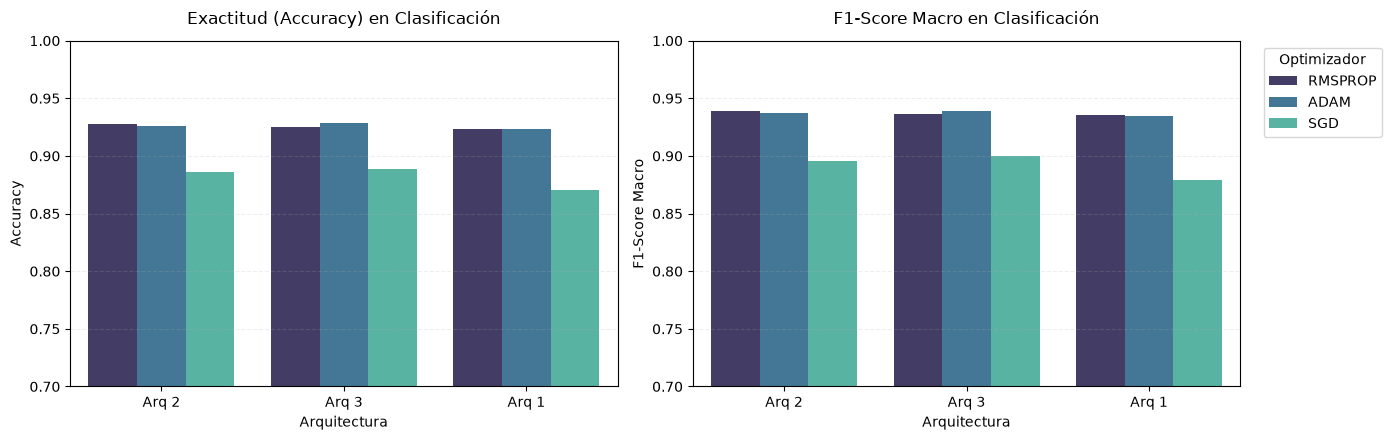

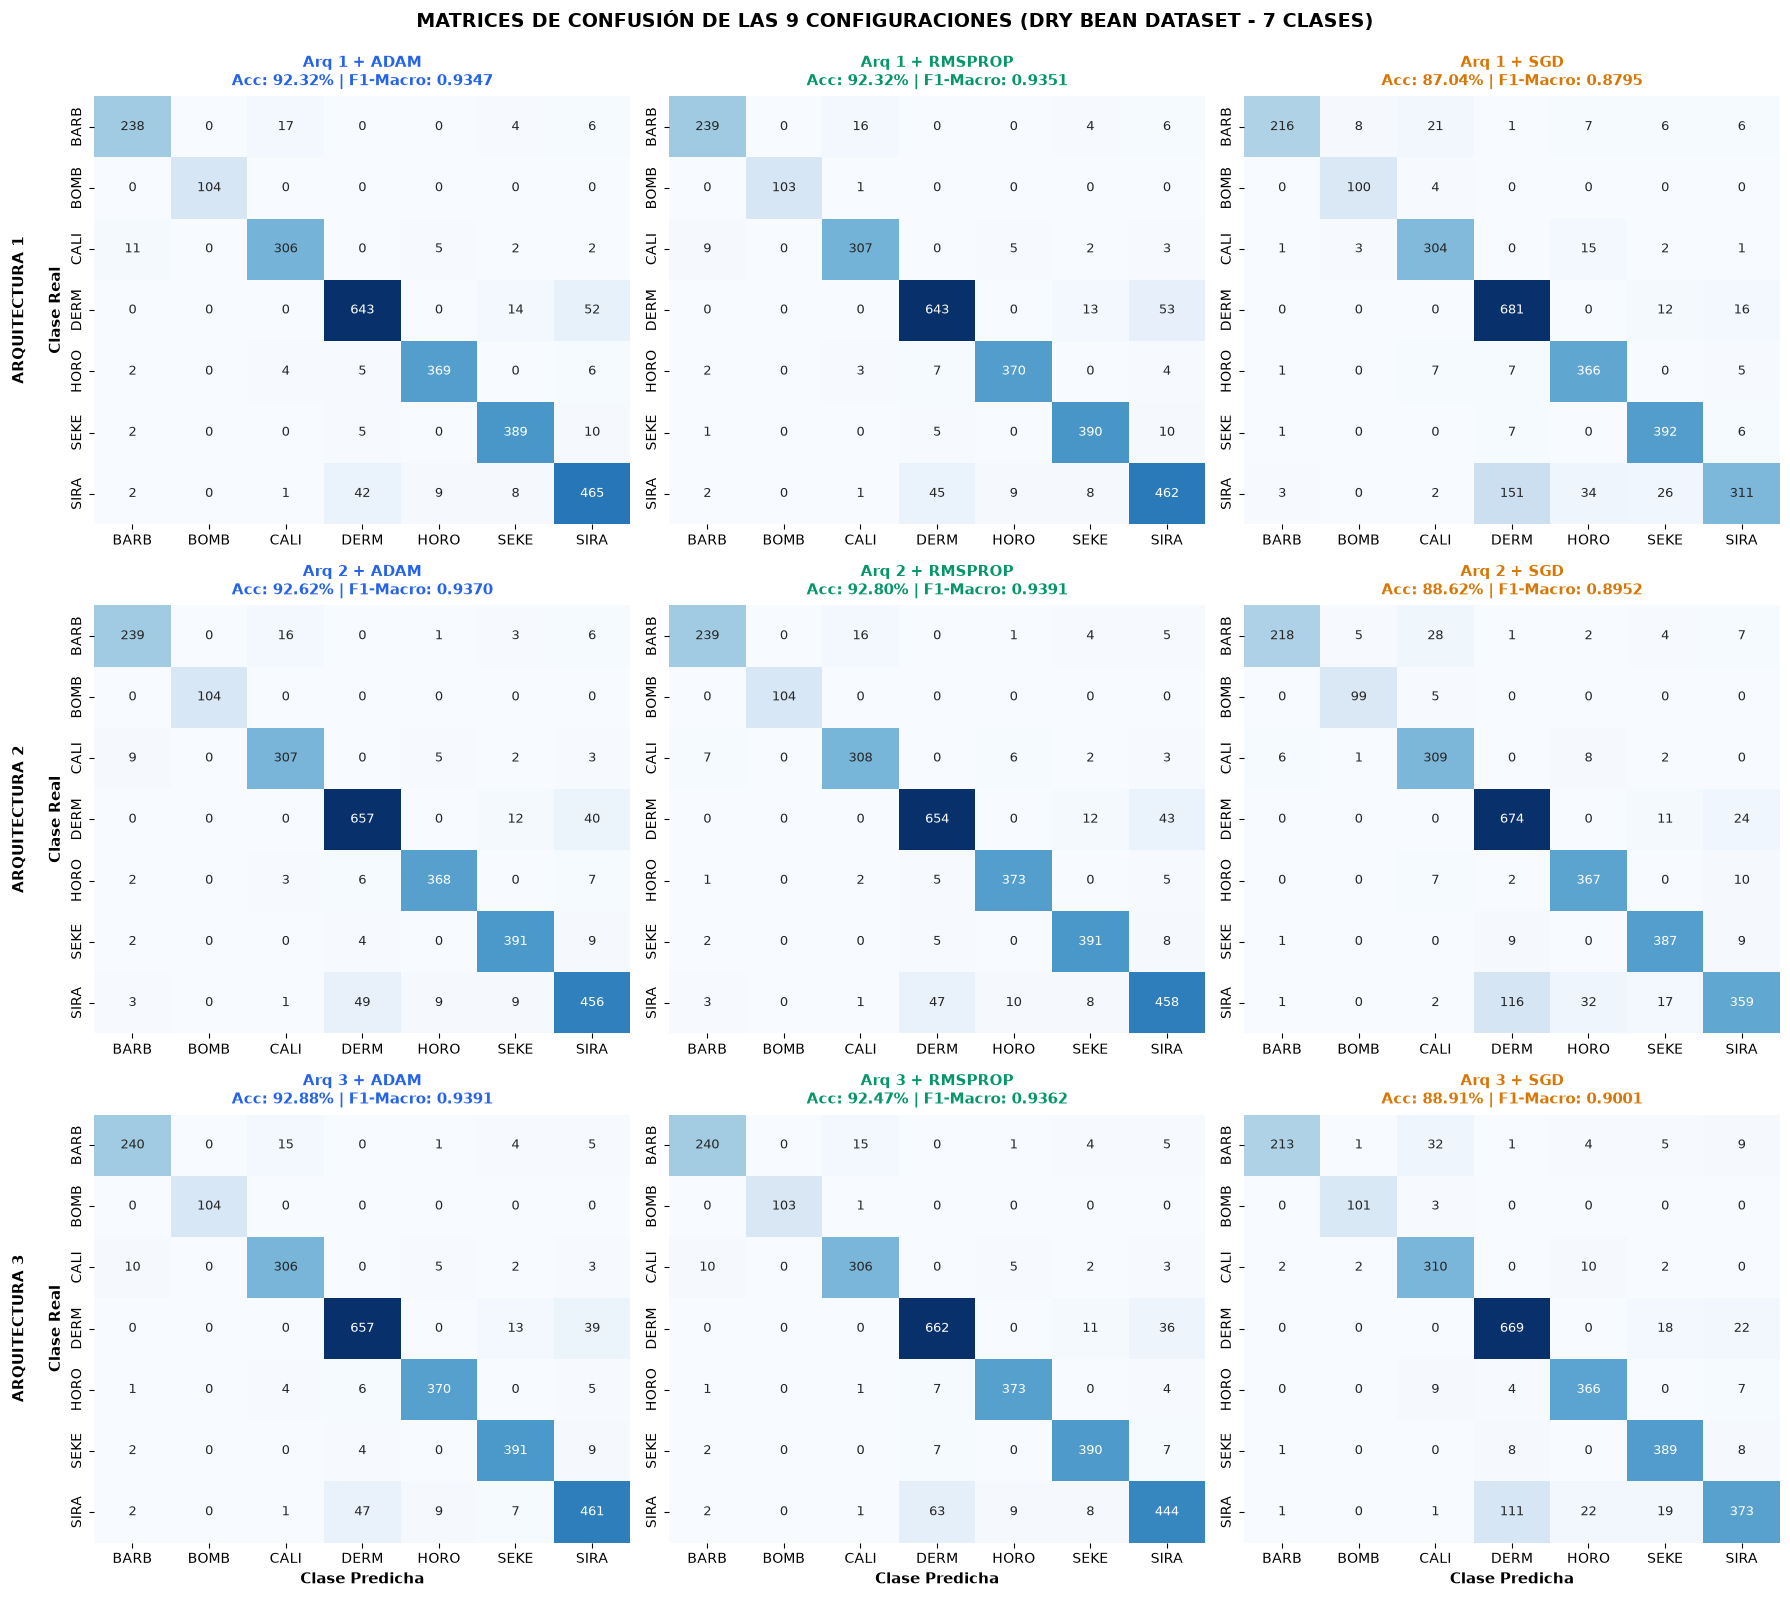

In [6]:
# 4. Gráfica Comparativa de Clasificación (Leyenda lateral limpia)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=df_res_clasif, x='Arquitectura', y='Accuracy', hue='Optimizador', palette='mako', ax=axes[0])
axes[0].set_title('Exactitud (Accuracy) en Clasificación', fontsize=12, pad=12)
axes[0].set_ylim(0.7, 1.0)
axes[0].set_ylabel('Accuracy')
axes[0].grid(axis='y', linestyle='--', alpha=0.2)
axes[0].get_legend().remove()

sns.barplot(data=df_res_clasif, x='Arquitectura', y='F1 Macro', hue='Optimizador', palette='mako', ax=axes[1])
axes[1].set_title('F1-Score Macro en Clasificación', fontsize=12, pad=12)
axes[1].set_ylim(0.7, 1.0)
axes[1].set_ylabel('F1-Score Macro')
axes[1].grid(axis='y', linestyle='--', alpha=0.2)

axes[1].legend(title='Optimizador', bbox_to_anchor=(1.03, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Grilla 3x3: Las 9 Matrices de Confusión para Clasificación (Dry Bean - 7 Clases)
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

arqs = [1, 2, 3]
opts = ['adam', 'rmsprop', 'sgd']

# Usamos nombres cortos de las 7 clases para que la matriz 7x7 se lea con total claridad
etiquetas_cortas = [c[:4].upper() for c in le_bean.classes_]

for fila, arq in enumerate(arqs):
    for col, opt in enumerate(opts):
        nombre_exp = f"Arq_{arq}_{opt}"
        ax = axes[fila, col]
        
        # Predicción y matriz de confusión
        modelo = modelos_clasif[nombre_exp]
        y_prob = modelo.predict(X_test_c, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        cm = confusion_matrix(y_test_c, y_pred)
        
        acc = accuracy_score(y_test_c, y_pred)
        f1 = f1_score(y_test_c, y_pred, average='macro', zero_division=0)
        
        # Gráfica del heatmap 7x7
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    annot_kws={"size": 9},
                    xticklabels=etiquetas_cortas,
                    yticklabels=etiquetas_cortas)
        
        # Título del subplot
        color_tit = '#2563eb' if opt == 'adam' else ('#059669' if opt == 'rmsprop' else '#d97706')
        ax.set_title(f"Arq {arq} + {opt.upper()}\nAcc: {acc:.2%} | F1-Macro: {f1:.4f}", 
                     fontsize=11, fontweight='bold', color=color_tit, pad=8)
        
        # Solo poner etiquetas en los bordes para mantener el diseño limpio
        if col == 0:
            ax.set_ylabel(f'ARQUITECTURA {arq}\n\nClase Real', fontweight='bold', fontsize=11)
        else:
            ax.set_ylabel('')
            
        if fila == 2:
            ax.set_xlabel('Clase Predicha', fontweight='bold', fontsize=11)
        else:
            ax.set_xlabel('')

plt.suptitle('MATRICES DE CONFUSIÓN DE LAS 9 CONFIGURACIONES (DRY BEAN DATASET - 7 CLASES)', 
             fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


★ MEJOR MODELO DE CLASIFICACIÓN: Arq_2_rmsprop ★


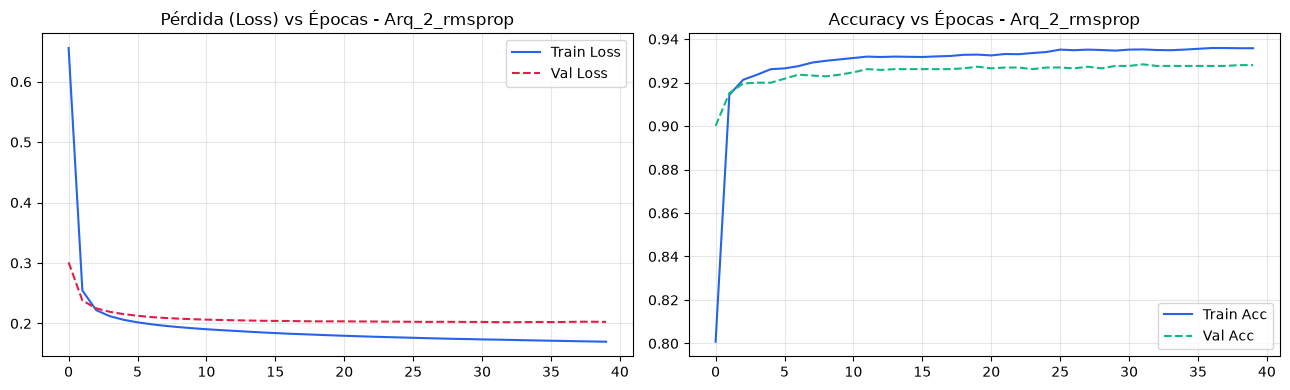


Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.90      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.96      0.97      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.88      0.87      0.87       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



In [7]:
# 5. Matriz de Confusión y Curvas de Aprendizaje del Mejor Modelo de Clasificación
mejor_c_nom = df_res_clasif.iloc[0]['Experimento']
mejor_c_mod = modelos_clasif[mejor_c_nom]
mejor_c_hist = historias_clasif[mejor_c_nom]

print(f"★ MEJOR MODELO DE CLASIFICACIÓN: {mejor_c_nom} ★")

# Curvas de Aprendizaje
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.plot(mejor_c_hist.history['loss'], label='Train Loss', color='#2563eb')
plt.plot(mejor_c_hist.history['val_loss'], label='Val Loss', color='#e11d48', linestyle='--')
plt.title(f'Pérdida (Loss) vs Épocas - {mejor_c_nom}')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(mejor_c_hist.history['accuracy'], label='Train Acc', color='#2563eb')
plt.plot(mejor_c_hist.history['val_accuracy'], label='Val Acc', color='#10b981', linestyle='--')
plt.title(f'Accuracy vs Épocas - {mejor_c_nom}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


y_prob_c = mejor_c_mod.predict(X_test_c, verbose=0)
y_pred_c = np.argmax(y_prob_c, axis=1)

print("\nReporte de Clasificación Detallado:")
print(classification_report(y_test_c, y_pred_c, target_names=le_bean.classes_))

---
# PARTE 2: PUNTO 2 - REGRESIÓN CONTINUA (BIKE SHARING DATASET)

### 🚴 Contexto del Problema:
Los sistemas de bicicletas compartidas (*Bike Sharing*) son una alternativa clave de movilidad sostenible en grandes urbes. Uno de los mayores retos operativos para las ciudades es **predecir la demanda horaria** para redistribuir la flota de bicicletas oportunamente entre estaciones y evitar estaciones vacías durante horas pico o eventos climáticos. Este dataset registra el uso horario del sistema *Capital Bikeshare* (Washington D.C.) durante 2 años (2011-2012), cruzado con información meteorológica oficial.

### 📋 Ficha Técnica del Dataset:
| Atributo | Detalle |
| :--- | :--- |
| **Fuente Oficial** | UCI Machine Learning Repository (Fanaee-T & Gama, 2014) |
| **Volumen** | **17,379 registros horarios** y 16 variables de entrada |
| **Tipo de Problema** | **Regresión Continua** (aproximación numérica de demanda) |
| **Variable Objetivo ($y$)** | `cnt` (Total de bicicletas alquiladas por hora: rango de 1 a 977) |
| **Datos Faltantes** | **0 valores nulos** (100% limpio) |

### 🔬 Entradas de la Red Neuronal ($X$):
- **Variables Temporales:** `season` (estación 1 a 4), `yr` (año), `mnth` (mes), `hr` (hora 0 a 23), `holiday` (festivo: 0 o 1), `weekday` (día de semana), `workingday` (día laboral: 0 o 1).
- **Variables Meteorológicas:** `weathersit` (condición climática: despejado, niebla, lluvia ligera, lluvia intensa), `temp` (temperatura normalizada), `atemp` (sensación térmica normalizada), `hum` (humedad relativa normalizada), `windspeed` (velocidad del viento normalizada).
*(Nota metodológica: se descartan `instant`, `dteday`, y las columnas `casual` y `registered` cuya suma da directamente `cnt`, evitando fuga del objetivo).*

✓ [Punto 2: Bike Sharing] Cargado con éxito: 17379 filas y 17 columnas.
✓ Auditoría de nulos: 0 valores faltantes (100% íntegro).


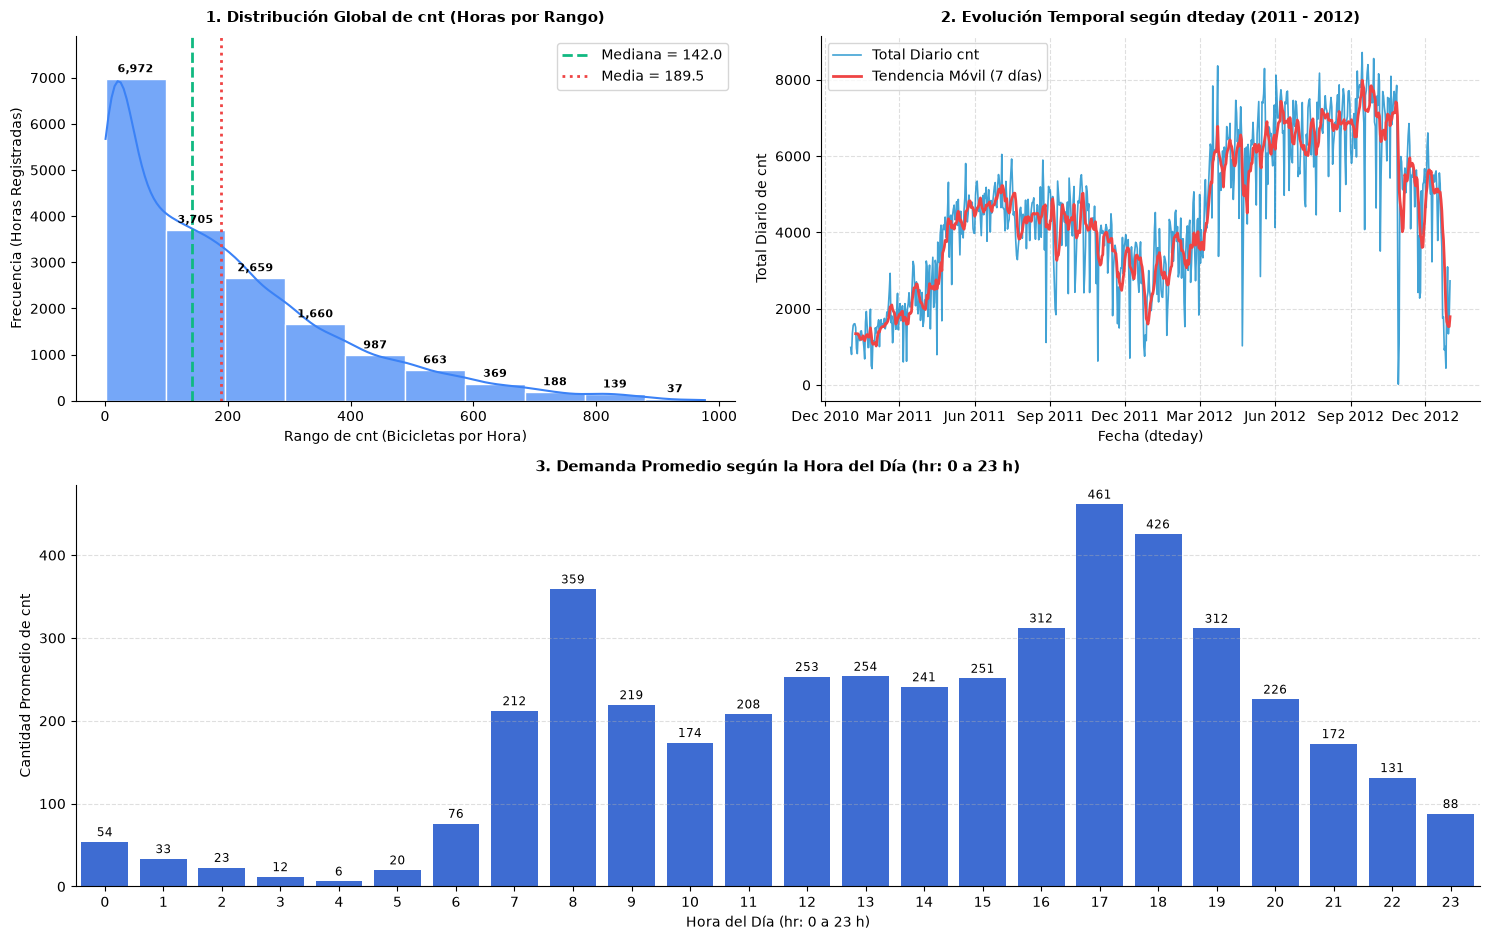

✓ Datos procesados: Train (13903, 12), Test (3476, 12) | Variables: 12


In [8]:
# 1. Carga y Auditoría de Bike Sharing
ruta_bike = '../Data_entrenamiento/Punto_2_Regresion/hour.csv'
df_bike = cargar_datos(ruta_bike, "Punto 2: Bike Sharing")
auditar_calidad_datos(df_bike, col_target='cnt', tipo='regresion', col_tiempo='dteday', col_ciclo='hr')

# 2. Preparación y escalado
# Descartamos columnas de ID, fecha y componentes desagregados (casual, registered) para evitar fuga de target
cols_drop_bike = ['instant', 'dteday', 'casual', 'registered']
X_train_r, X_test_r, y_train_r, y_test_r, scaler_r, _ = preparar_datos(
    df=df_bike, col_target='cnt', cols_a_eliminar=cols_drop_bike, tipo='regresion'
)

In [9]:
# 3. Experimentación Sistemática en Regresión (3 Arq x 3 Opt = 9 Modelos)
input_dim_r = X_train_r.shape[1]

resultados_regres = []
historias_regres = {}
modelos_regres = {}

print("Entrenando 9 configuraciones para Regresión (Bike Sharing)...")
for arq in arqs:
    for opt in opts:
        nombre = f"Arq_{arq}_{opt}"
        print(f"-> {nombre}...", end=" ")
        
        m = construir_mlp(arq, input_dim_r, output_dim=1, tipo='regresion', optimizador=opt, lr=0.001)
        h = m.fit(
            X_train_r, y_train_r,
            epochs=40, batch_size=64,
            validation_data=(X_test_r, y_test_r),
            verbose=0
        )
        
        y_pred_r = m.predict(X_test_r, verbose=0).flatten()
        
        r2 = r2_score(y_test_r, y_pred_r)
        rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
        mae = mean_absolute_error(y_test_r, y_pred_r)
        
        resultados_regres.append({
            'Experimento': nombre,
            'Arquitectura': f"Arq {arq}",
            'Optimizador': opt.upper(),
            'R2 Score': round(r2, 4),
            'RMSE': round(rmse, 2),
            'MAE': round(mae, 2)
        })
        historias_regres[nombre] = h
        modelos_regres[nombre] = m
        print(f"Listo | R²: {r2:.4f}, RMSE: {rmse:.2f}")

df_res_regres = pd.DataFrame(resultados_regres).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
print("\n--- TABLA COMPARATIVA: REGRESIÓN ---")
display(df_res_regres)

Entrenando 9 configuraciones para Regresión (Bike Sharing)...
-> Arq_1_adam... 

Listo | R²: 0.4945, RMSE: 126.52
-> Arq_1_rmsprop... 

Listo | R²: 0.4679, RMSE: 129.81
-> Arq_1_sgd... 

Listo | R²: 0.1220, RMSE: 166.74
-> Arq_2_adam... 

Listo | R²: 0.6642, RMSE: 103.12
-> Arq_2_rmsprop... 

...

Listo | R²: 0.4052, RMSE: 137.24
-> Arq_3_adam... 

Listo | R²: 0.6651, RMSE: 102.98
-> Arq_3_rmsprop... 

Listo | R²: 0.6605, RMSE: 103.69
-> Arq_3_sgd... 

Listo | R²: 0.4019, RMSE: 137.62

--- TABLA COMPARATIVA: REGRESIÓN ---


,Experimento,Arquitectura,Optimizador,R2 Score,RMSE,MAE
0,Arq_3_adam,Arq 3,ADAM,0.6651,102.98,71.14
1,Arq_2_adam,Arq 2,ADAM,0.6642,103.12,72.17
2,Arq_3_rmsprop,Arq 3,RMSPROP,0.6605,103.69,70.33
3,Arq_2_rmsprop,Arq 2,RMSPROP,0.6458,105.91,74.33
4,Arq_1_adam,Arq 1,ADAM,0.4945,126.52,91.37
5,Arq_1_rmsprop,Arq 1,RMSPROP,0.4679,129.81,93.93
6,Arq_2_sgd,Arq 2,SGD,0.4052,137.24,101.87
7,Arq_3_sgd,Arq 3,SGD,0.4019,137.62,101.47
8,Arq_1_sgd,Arq 1,SGD,0.1220,166.74,109.39


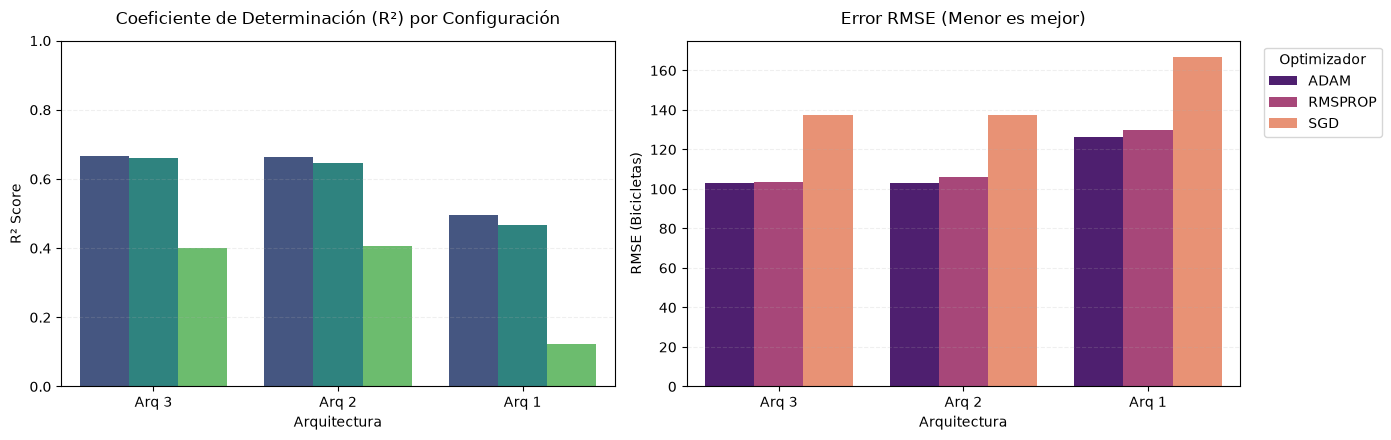

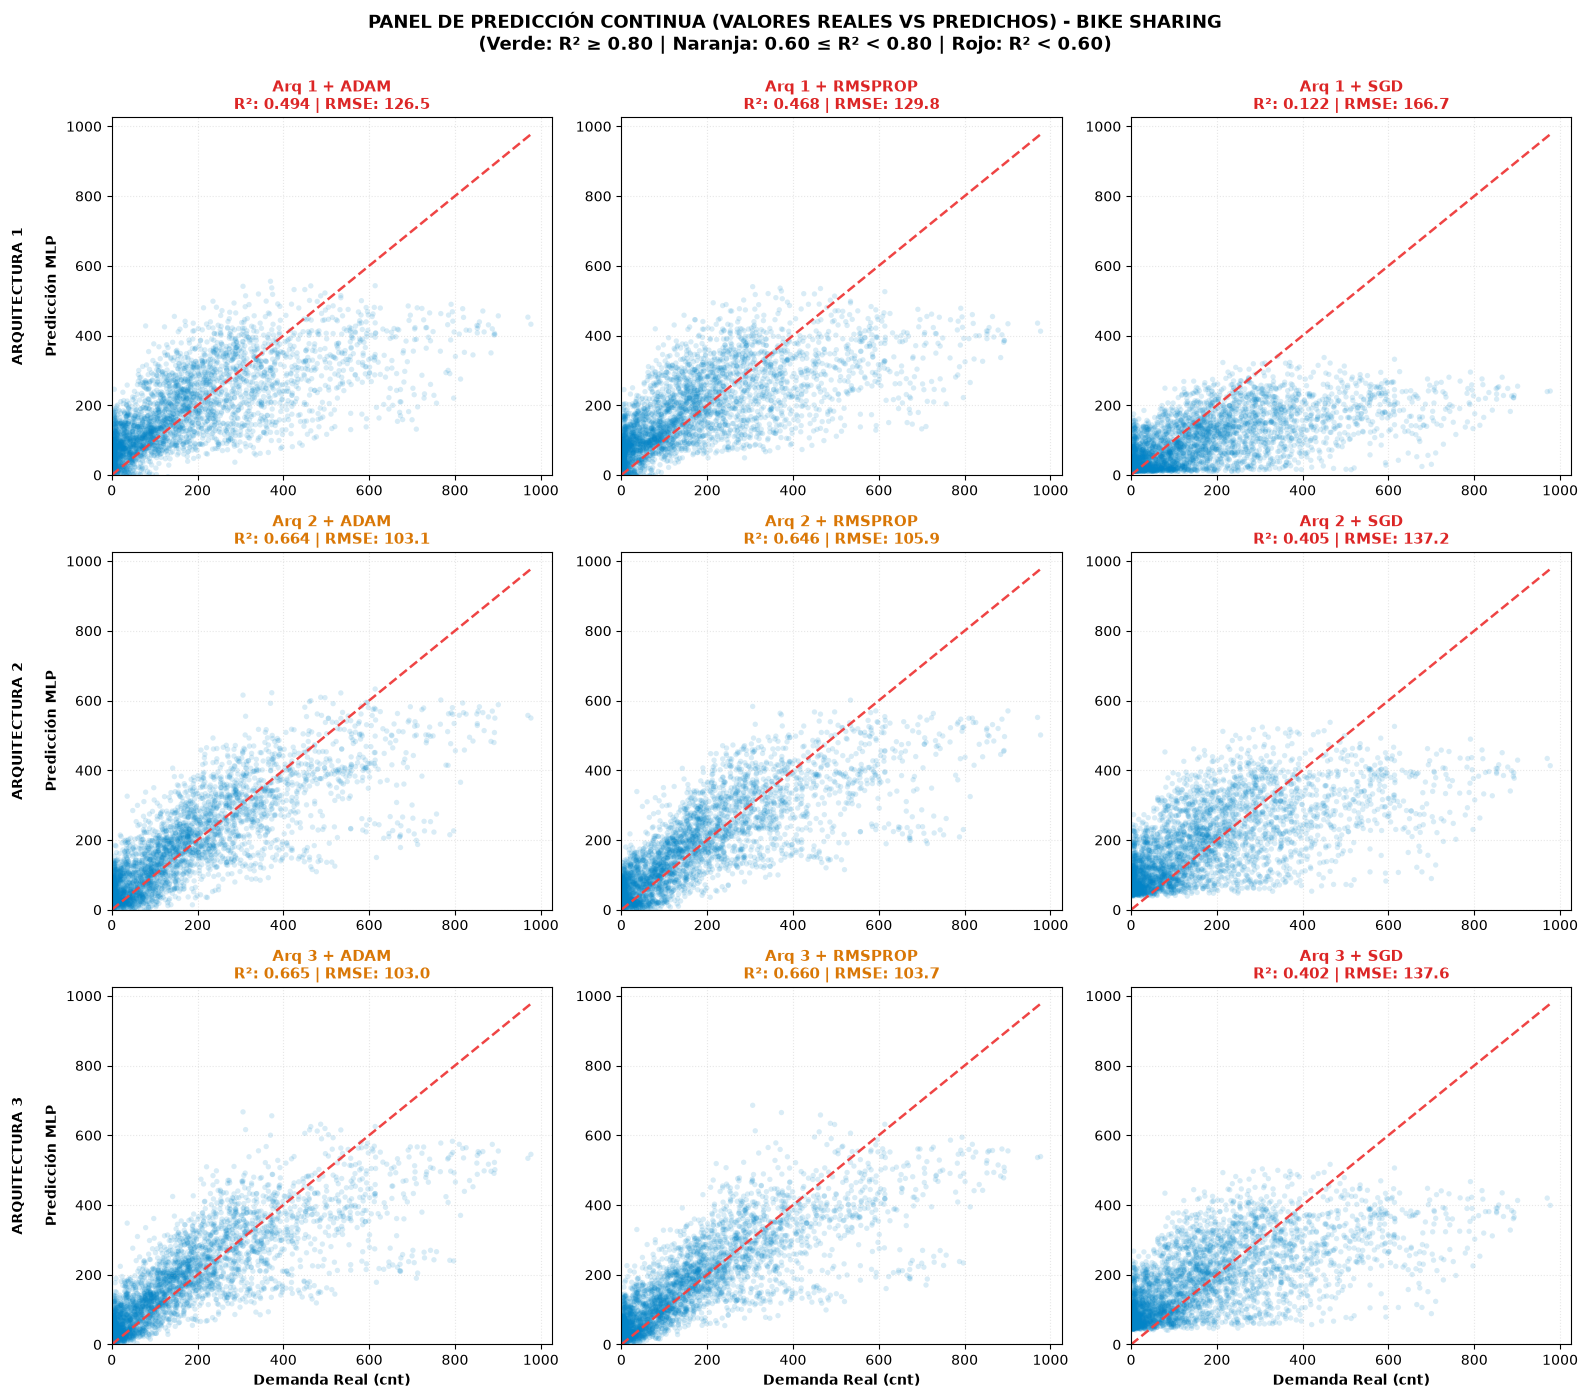

In [10]:
# 4. Gráfica Comparativa de Regresión (R² y RMSE)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(data=df_res_regres, x='Arquitectura', y='R2 Score', hue='Optimizador', palette='viridis', ax=axes[0])
axes[0].set_title('Coeficiente de Determinación (R²) por Configuración', fontsize=12, pad=12)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_ylabel('R² Score')
axes[0].grid(axis='y', linestyle='--', alpha=0.2)
axes[0].get_legend().remove()

sns.barplot(data=df_res_regres, x='Arquitectura', y='RMSE', hue='Optimizador', palette='magma', ax=axes[1])
axes[1].set_title('Error RMSE (Menor es mejor)', fontsize=12, pad=12)
axes[1].set_ylabel('RMSE (Bicicletas)')
axes[1].grid(axis='y', linestyle='--', alpha=0.2)

axes[1].legend(title='Optimizador', bbox_to_anchor=(1.03, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


# Grilla 3x3: Dispersión Real vs Predicho para los 9 Modelos de Regresión (Bike Sharing)
fig, axes = plt.subplots(3, 3, figsize=(16, 14))

arqs = [1, 2, 3]
opts = ['adam', 'rmsprop', 'sgd']

max_val = y_test_r.max()

for fila, arq in enumerate(arqs):
    for col, opt in enumerate(opts):
        nombre_exp = f"Arq_{arq}_{opt}"
        ax = axes[fila, col]
        
        # Obtener predicciones
        modelo = modelos_regres[nombre_exp]
        y_pred = modelo.predict(X_test_r, verbose=0).flatten()
        
        # Calcular métricas
        r2 = r2_score(y_test_r, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test_r, y_pred))
        
        # Gráfica de dispersión
        ax.scatter(y_test_r, y_pred, alpha=0.15, color='#0284c7', s=15, edgecolors='none')
        
        # Línea de referencia ideal y = x (predicción perfecta)
        ax.plot([0, max_val], [0, max_val], color='#ef4444', linestyle='--', lw=1.8, label='Ideal (y=x)')
        
        # Título con métricas
        color_tit = '#16a34a' if r2 >= 0.80 else ('#d97706' if r2 >= 0.60 else '#dc2626')
        ax.set_title(f"Arq {arq} + {opt.upper()}\nR²: {r2:.3f} | RMSE: {rmse:.1f}", 
                     fontsize=10.5, fontweight='bold', color=color_tit, pad=6)
        
        ax.set_xlim(0, max_val * 1.05)
        ax.set_ylim(0, max_val * 1.05)
        ax.grid(True, linestyle=':', alpha=0.3)
        
        # Etiquetas limpias solo en bordes
        if col == 0:
            ax.set_ylabel(f'ARQUITECTURA {arq}\n\nPredicción MLP', fontweight='bold', fontsize=10)
        else:
            ax.set_ylabel('')
            
        if fila == 2:
            ax.set_xlabel('Demanda Real (cnt)', fontweight='bold', fontsize=10)
        else:
            ax.set_xlabel('')

plt.suptitle('PANEL DE PREDICCIÓN CONTINUA (VALORES REALES VS PREDICHOS) - BIKE SHARING\n(Verde: R² ≥ 0.80 | Naranja: 0.60 ≤ R² < 0.80 | Rojo: R² < 0.60)', 
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


★ MEJOR MODELO DE REGRESIÓN: Arq_3_adam (R² = 0.6651) ★


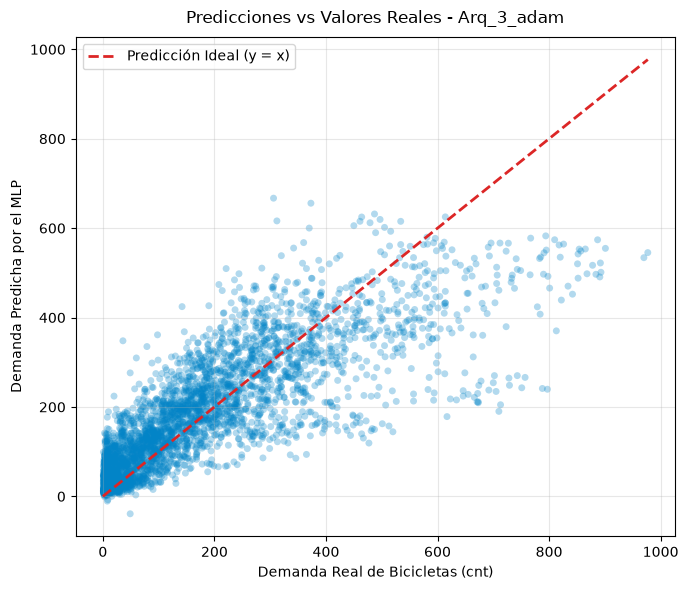

In [11]:
# 5. Análisis del Mejor Modelo de Regresión: Gráfica de Dispersión Real vs Predicho
mejor_r_nom = df_res_regres.iloc[0]['Experimento']
mejor_r_mod = modelos_regres[mejor_r_nom]
mejor_r_hist = historias_regres[mejor_r_nom]

print(f"★ MEJOR MODELO DE REGRESIÓN: {mejor_r_nom} (R² = {df_res_regres.iloc[0]['R2 Score']}) ★")

y_pred_mejor_r = mejor_r_mod.predict(X_test_r, verbose=0).flatten()

# Gráfica de Dispersión Real vs Predicho
plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, y_pred_mejor_r, alpha=0.3, color='#0284c7', edgecolors='none', s=25)
# Línea de predicción perfecta y = x
max_val = max(y_test_r.max(), y_pred_mejor_r.max())
plt.plot([0, max_val], [0, max_val], color='#dc2626', linestyle='--', lw=2, label='Predicción Ideal (y = x)')

plt.title(f'Predicciones vs Valores Reales - {mejor_r_nom}', fontsize=12, pad=10)
plt.xlabel('Demanda Real de Bicicletas (cnt)')
plt.ylabel('Demanda Predicha por el MLP')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 5. Conclusiones Generales del Taller

1. **Reutilización y Modularidad:** El diseño de un pipeline basado en funciones parametrizables, en esta parte comprendi mucho mas a fondo las estructuras de los dos problema ya que al revisando el codigo e investigando entendi realmente que son muy parecedidos.


2. **Impacto de la Profundidad según la Tarea:**:

    Para la regresión continua, entre mas profunda la red mejor son los resultados. [Esto solo para este experimento], por que estamos hablando que el dataset talvez tenia variables que no explicaban muy bien los datos, dependiamos del comportamiento de muchas personas.

    Para la Clasificación, una sola capa oculta (Arq 1) ya alcanzaba un 92.3% de exactitud, mostrando que los límites de separación geométrica del fríjol eran menos sensibles y las mejoras fueron importantes pero no tan grandes a medida que se agregaban capas.


3. **Dominio de Optimizadores Adaptativos:** 
 
Los algoritmos con tasa de aprendizaje adaptativa (`RMSprop` y `Adam`) superaron con contundencia a `SGD con Momentum` en ambas tareas. 


4. **Eficiencia y Parsimonia frente al Sobreajuste:** 
Básicamente, la conclusión aquí es que más grande no siempre es mejor. La Arquitectura 3 necesitaba Dropout para no memorizar por tener tantas neuronas. En cambio, la Arquitectura 2, con la mitad de neuronas y sin Dropout, logró los mismos resultados sin complicarse. Si dimensionas bien la red desde el principio, no necesitas parches para evitar el sobreajuste."

Podria Resumirse en que siempre es importante evaluar los modelos con diferentes configuraciónes de arquitectura para encontrar el que mejor explique o realice la tarea.

---

## 6. Referencias
1. **Caicedo Bravo, E. F., & López Sotelo, J. A. (2009).** *Una aproximación práctica a las redes neuronales artificiales* (Cap. 3: Perceptrón Multicapa y Algoritmo Backpropagation, pp. 76–86). Programa Editorial Universidad del Valle. https://doi.org/10.25100/peu.64
2. ** Gemini 3.8 Flash ** Se usa ia para explicar el codigo y explicar concepto que no tenia claro
